Вариант 1

ПрО-1. Оптимизация рациона питания с учётом стоимости и разнообразия 
Данные: список блюд (калории, белки, жиры, углеводы, стоимость и категория). 
Цель: выбрать набор блюд (от 3 до 7) так, чтобы суммарные калории и БЖУ были максимально близки к целевым значениям, стоимость не превышала бюджет и количество блюд из одной категории не более двух. 
Кодирование: целочисленный массив переменной длины или вещественное кодирование весов порций. 

ТГА-1. Базовый набор 
Кодирование: фиксированная длина, целочисленное/бинарное (по выбору). 
Кроссинговер: одноточечный. 
Мутация: одноточечная (замена одного гена). 
Отбор: рулетка. 
Элитизм: не используется. 

ЭКС-1. Исследование гиперпараметров 
Провести поиск по сетке для размера популяции (3 значения), вероятности мутации (3 значения) и размера брачного пула (2 значения). Построить тепловые карты для лучшего значения фитнес-функции и времени работы. Оценить влияние каждого параметра. 

In [1]:
import pandas as pd

categories = {
    1 : "завтрак",
    2 : "обед",
    3 : "ужин",
    4 : "перекус"
}

food = {
    "творог": (180, 16.0, 9.0, 3.0, 120, 1),
    "овсяная каша": (350, 10.0, 6.0, 68.0, 80, 1),
    "омлет с сыром": (280, 18.0, 20.0, 4.0, 100, 1),
    "каша рисовая на молоке": (310, 8.0, 7.0, 55.0, 90, 1),
    "гречка с курицей": (450, 35.0, 8.0, 55.0, 180, 2),
    "рыба с рисом": (390, 30.0, 12.0, 40.0, 250, 2),
    "макароны с фаршем": (580, 25.0, 22.0, 65.0, 150, 2),
    "суп куриный с лапшой": (210, 14.0, 7.0, 22.0, 130, 2),
    "овощной салат": (150, 4.0, 10.0, 12.0, 90, 3),
    "бутерброд с сыром": (320, 12.8, 16.2, 29.6, 60, 3),
    "йогурт": (120, 5.0, 3.5, 14.0, 70, 3),
    "орехи": (200, 7.0, 18.0, 6.0, 110, 3),
    "банан": (95, 1.5, 0.5, 21.0, 40, 4),
    "яблоко": (45, 0.4, 0.4, 9.8, 30, 4),
    "апельсин": (45, 0.9, 0.2, 8.1, 50, 4),
    "груша": (55, 0.4, 0.3, 13.0, 60, 4),
}

df = pd.DataFrame(columns=["name", "cal", "prt", "fat", "crb", "cost", "category"])

for name, pfc in food.items():
    df.loc[len(df.index)] = [name, pfc[0], pfc[1], pfc[2], pfc[3], pfc[4], pfc[5]]

df

,name,cal,prt,fat,crb,cost,category
0,творог,180,16.0,9.0,3.0,120,1
1,овсяная каша,350,10.0,6.0,68.0,80,1
2,омлет с сыром,280,18.0,20.0,4.0,100,1
3,каша рисовая на молоке,310,8.0,7.0,55.0,90,1
4,гречка с курицей,450,35.0,8.0,55.0,180,2
5,рыба с рисом,390,30.0,12.0,40.0,250,2
6,макароны с фаршем,580,25.0,22.0,65.0,150,2
7,суп куриный с лапшой,210,14.0,7.0,22.0,130,2
8,овощной салат,150,4.0,10.0,12.0,90,3
9,бутерброд с сыром,320,12.8,16.2,29.6,60,3


In [55]:
from typing import List
import numpy as np
from pandas import DataFrame

def my_print(df:DataFrame, data: List[List[int]]) -> List[List[str]]:
    return [[str(df.loc[element]["name"]) for element in item] for item in data]



GENE_SIZE = 4
POPULATION_COUNT = [30, 60, 90] 
MUTATION_PROBS = [0.05, 0.15, 0.25]
MATING_POOL_RATIOS = [0.3, 0.5] 
SEED = 42

generator = np.random.default_rng(SEED)

from typing import List, Dict
import random

def my_population(food: List[int], count: int, size: int, 
                  food_categories: Dict[int, str]) -> List[List[int]]:
    population: List[List[int]] = []
    max_attempts_per_chromosome = 1000
    
    while len(population) < count:
        for _ in range(max_attempts_per_chromosome):
            element: List[int] = []
            used_indices = set()
            category_count: Dict[str, int] = {}
            valid = True
            
            for position in range(size):
                available = []
                for idx, food_item in enumerate(food):
                    if idx in used_indices:
                        continue
                    
                    category = food_categories.get(food_item, "unknown")
                    
                    if category_count.get(category, 0) < 2:
                        available.append((idx, food_item))
                
                if not available:
                    valid = False
                    break
                
                chosen_idx, chosen_food = random.choice(available)
                element.append(chosen_food)
                used_indices.add(chosen_idx)
                
                category = food_categories.get(chosen_food, "unknown")
                category_count[category] = category_count.get(category, 0) + 1
            
            if valid and len(element) == size:
                population.append(element)
                break
        else:
            fallback = []
            seen_categories = {}
            for food_item in food:
                category = food_categories.get(food_item, "unknown")
                if len(fallback) < size and seen_categories.get(category, 0) < 2:
                    fallback.append(food_item)
                    seen_categories[category] = seen_categories.get(category, 0) + 1
            population.append(fallback)
    
    return population


food_categories = {
    0: "завтрак", 1: "завтрак", 2: "завтрак", 3: "завтрак",
    4: "обед", 5: "обед", 6: "обед", 7: "обед",
    8: "перекус", 9: "перекус", 10: "фрукты", 11: "фрукты"
}

population = my_population(
    food=list(df.index.values),
    count=30,
    size=5,
    food_categories=food_categories
)

for i, chrom in enumerate(population):
    print(f"Хромосома {i}: {chrom}")

Хромосома 0: [np.int64(14), np.int64(9), np.int64(12), np.int64(7), np.int64(10)]
Хромосома 1: [np.int64(3), np.int64(10), np.int64(1), np.int64(8), np.int64(14)]
Хромосома 2: [np.int64(11), np.int64(8), np.int64(15), np.int64(14), np.int64(0)]
Хромосома 3: [np.int64(14), np.int64(8), np.int64(3), np.int64(7), np.int64(1)]
Хромосома 4: [np.int64(7), np.int64(4), np.int64(0), np.int64(12), np.int64(9)]
Хромосома 5: [np.int64(11), np.int64(14), np.int64(15), np.int64(1), np.int64(8)]
Хромосома 6: [np.int64(3), np.int64(13), np.int64(14), np.int64(4), np.int64(5)]
Хромосома 7: [np.int64(11), np.int64(14), np.int64(12), np.int64(9), np.int64(6)]
Хромосома 8: [np.int64(5), np.int64(10), np.int64(2), np.int64(15), np.int64(4)]
Хромосома 9: [np.int64(6), np.int64(13), np.int64(0), np.int64(11), np.int64(7)]
Хромосома 10: [np.int64(8), np.int64(10), np.int64(9), np.int64(2), np.int64(6)]
Хромосома 11: [np.int64(9), np.int64(4), np.int64(11), np.int64(5), np.int64(14)]
Хромосома 12: [np.int64(3

In [56]:
import numpy as np

def my_fitness(chromosome, df, 
            target_cal=1800, target_prt=120, target_fat=60, target_crb=200,
            budget=600):
    
    chromosome = [int(x) for x in chromosome]
    total = df.loc[chromosome][["cal", "prt", "fat", "crb", "cost"]].sum()

    nutri_error = (
        abs(total["cal"] - target_cal) +
        abs(total["prt"] - target_prt) +
        abs(total["fat"] - target_fat) +
        abs(total["crb"] - target_crb)
    )

    budget_penalty = 0
    if total["cost"] > budget:
        budget_penalty = (total["cost"] - budget) * 50

    unique_count = len(set(chromosome))
    duplicate_penalty = (len(chromosome) - unique_count) * 500 

    category_counts = df.loc[chromosome]["category"].value_counts()
    category_penalty = 0
    for count in category_counts:
        if count > 2:
            category_penalty += (count - 2) * 50

    fitness_value = nutri_error + budget_penalty + duplicate_penalty + category_penalty

    return fitness_value

scores = [my_fitness(ch, df) for ch in population]
best_idx = np.argmin(scores)
best_chrom = population[best_idx]
print(scores)
print(f"Лучший хромосома: {best_chrom} с фитнесом {scores[best_idx]}")


[np.float64(1233.6999999999998), np.float64(993.3), np.float64(1442.1000000000001), np.float64(882.8), np.float64(674.4), np.float64(1216.1000000000001), np.float64(670.2), np.float64(706.2), np.float64(3626.8), np.float64(740.4000000000001), np.float64(542.3), np.float64(2996.2), np.float64(408.9), np.float64(2151.3), np.float64(215.0), np.float64(1056.8000000000002), np.float64(768.2), np.float64(936.3), np.float64(2979.3), np.float64(1309.2), np.float64(1013.5), np.float64(825.4000000000001), np.float64(3272.8), np.float64(552.8), np.float64(879.3000000000001), np.float64(784.4000000000001), np.float64(673.0), np.float64(2029.3), np.float64(768.2), np.float64(2576.4)]
Лучший хромосома: [np.int64(4), np.int64(12), np.int64(6), np.int64(3), np.int64(11)] с фитнесом 215.0


In [4]:
generator = np.random.default_rng(SEED)

def my_crossover(item1: List[int], item2: List[int], size: int) -> List[int]:
    new_item = item1.copy()
    random_split_point = generator.choice(range(size - 1))
    new_item[random_split_point:] = item2[random_split_point:]
    return new_item

for _ in range(4):
    display(my_print(df, [my_crossover([1, 10, 9, 2], [7, 6, 3, 15], 4)]))

[['суп куриный с лапшой',
  'макароны с фаршем',
  'каша рисовая на молоке',
  'груша']]

[['овсяная каша', 'йогурт', 'каша рисовая на молоке', 'груша']]

[['овсяная каша', 'макароны с фаршем', 'каша рисовая на молоке', 'груша']]

[['овсяная каша', 'макароны с фаршем', 'каша рисовая на молоке', 'груша']]

In [5]:
generator = np.random.default_rng(SEED)

def my_mutation(
    food: List[int], population: List[List[int]], size: int, proba: float = 1.0, debug: bool = False
) -> List[List[int]]:
    for element in range(len(population)):
        if generator.random(1)[0] > proba:
            continue
        position = generator.choice(range(size - 1))
        new_value = generator.choice(range(len(food)))
        if debug:
            display(f"e={element + 1}; p={position + 1}; v={new_value + 1}")
        population[element][position] = food[new_value]
    return population


display(my_print(df, my_mutation(list(df.index.values), population[:4], GENE_SIZE, debug=True)))

'e=1; p=2; v=8'

'e=2; p=1; v=12'

'e=3; p=2; v=16'

'e=4; p=3; v=13'

[['творог', 'суп куриный с лапшой', 'груша', 'йогурт', 'орехи'],
 ['орехи', 'яблоко', 'творог', 'овощной салат', 'рыба с рисом'],
 ['орехи', 'груша', 'апельсин', 'бутерброд с сыром', 'макароны с фаршем'],
 ['гречка с курицей', 'апельсин', 'банан', 'яблоко', 'овсяная каша']]

In [57]:
import time
import pandas as pd
import numpy as np
import pygad
from typing import Dict, Any, List
import warnings
warnings.filterwarnings('ignore')

POPULATION_SIZES = [30, 60, 120]
MUTATION_PROBS = [0.05, 0.15, 0.25] 
MATING_POOL_RATIOS = [0.3, 0.5] 
SEED = 42
GENE_SIZE = 4

generator = np.random.default_rng(SEED)

def fitness_func(ga_instance: pygad.GA, solution: list, solution_idx: int) -> float:
    fitness_value = my_fitness(solution, df)
    return 1 / (fitness_value + 0.000001)

def parent_selection_func(fitness: np.ndarray, num_parents: int, ga_instance: pygad.GA) -> tuple:
    if ga_instance.population is None:
        raise ValueError("ga_instance.population is None")
    
    fitness_sorted = np.argsort(fitness)[::-1]    
    parents = ga_instance.population[fitness_sorted[:num_parents]].copy()
    return parents, np.array(fitness_sorted[:num_parents])

def rank_selection_func(fitness: np.ndarray, num_parents: int, ga_instance: pygad.GA) -> tuple:
    if ga_instance.population is None:
        raise ValueError("ga_instance.population is None")
    
    population_size = len(fitness)
    sorted_indices = np.argsort(fitness)[::-1]
    ranks = np.arange(population_size, 0, -1)
    selection_probs = ranks / np.sum(ranks)
    selected_indices = generator.choice(
        sorted_indices, 
        size=num_parents, 
        p=selection_probs,
        replace=False
    )
    
    parents = ga_instance.population[selected_indices].copy()
    return parents, selected_indices


def crossover_func(parents: np.ndarray, offspring_size: list, ga_instance: pygad.GA) -> np.ndarray:
    offspring = []
    idx = 0
    proba = ga_instance.crossover_probability or 0.0
    while len(offspring) != offspring_size[0]:
        parent1 = parents[idx % parents.shape[0], :].copy()
        parent2 = parents[(idx + 1) % parents.shape[0], :].copy()
        if generator.random() > proba:
            offspring.append(parent1)
        else:
            result = my_crossover(parent1.tolist(), parent2.tolist(), GENE_SIZE)
            offspring.append(result)
        idx += 1
    return np.array(offspring)

def mutation_func(offspring: np.ndarray, ga_instance: pygad.GA) -> np.ndarray:
    proba = ga_instance.mutation_probability or 0.0
    mutated = my_mutation(list(df.index.values), offspring.tolist(), GENE_SIZE, proba)
    return np.array(mutated, dtype=int)

def run_ga_with_params(population_size: int, mutation_prob: float, 
                       mating_pool_ratio: float, crossover_prob: float = 0.8,
                       verbose: bool = False) -> Dict[str, Any]:

    generator_local = np.random.default_rng(SEED)
    
    initial_population = my_population(
        food=list(df.index.values),
        count=population_size,
        size=GENE_SIZE,
        food_categories=food_categories
    )
    
    num_parents_mating = max(2, int(population_size * mating_pool_ratio))
    
    ga = pygad.GA(
        gene_type=int,
        gene_space=list(range(len(df))),
        num_generations=30,
        initial_population=initial_population,
        num_parents_mating=num_parents_mating,
        fitness_func=fitness_func,
        parent_selection_type=rank_selection_func, 
        crossover_type="uniform", 
        crossover_probability=crossover_prob,
        mutation_type="random", 
        mutation_probability=mutation_prob,
        mutation_by_replacement=True,
        save_best_solutions=True,
        suppress_warnings=True,
        stop_criteria=["saturate_10"], 
        random_seed=SEED,
    )
    
    start_time = time.time()
    ga.run()
    end_time = time.time()
    
    best_solution, best_fitness, generation_found = ga.best_solution()
    
    if verbose:
        print(f"  Поколений выполнено: {ga.generations_completed}")
        print(f"  Лучший фитнес: {best_fitness:.4f}")
        print(f"  Время: {end_time - start_time:.2f} сек")
    
    return {
        'population_size': population_size,
        'mutation_prob': mutation_prob,
        'crossover_prob': crossover_prob,
        'mating_pool_ratio': mating_pool_ratio,
        'num_parents_mating': num_parents_mating,
        'best_fitness': best_fitness,
        'execution_time': end_time - start_time,
        'generations_completed': ga.generations_completed,
        'generation_found': generation_found,
        'best_solution': best_solution.tolist() if isinstance(best_solution, np.ndarray) else best_solution
    }



all_results = []
total_combinations = len(POPULATION_SIZES) * len(MUTATION_PROBS) * len(MATING_POOL_RATIOS)
current = 0

for pop_size in POPULATION_SIZES:
    for mut_prob in MUTATION_PROBS:
        for mating_ratio in MATING_POOL_RATIOS:
            current += 1
            print(f"\nПопуляция={pop_size}, "
                    f"Мутация={mut_prob:.2f}, Брачный пул={mating_ratio:.1%}")
            
            try:
                result = run_ga_with_params(
                    population_size=pop_size,
                    mutation_prob=mut_prob,
                    mating_pool_ratio=mating_ratio,
                    crossover_prob=0.8,
                    verbose=True
                )
                all_results.append(result)
            except Exception as e:
                print(f"  ОШИБКА: {str(e)}")
                continue

if all_results:
    results_df = pd.DataFrame(all_results)
    
    display(results_df)
    
    print("\nстатистика ")
    
    best_idx = results_df['best_fitness'].idxmax()
    best_result = results_df.loc[best_idx]
    
    print("\nЛучший результат:")
    print(f"  Популяция: {best_result['population_size']}")
    print(f"  Мутация: {best_result['mutation_prob']:.2f}")
    print(f"  Брачный пул: {best_result['mating_pool_ratio']:.1%}")
    print(f"  Фитнес: {best_result['best_fitness']:.4f}")
    print(f"  Время: {best_result['execution_time']:.2f} сек")
    


Популяция=30, Мутация=0.05, Брачный пул=30.0%
  Поколений выполнено: 11
  Лучший фитнес: 0.0052
  Время: 0.25 сек

Популяция=30, Мутация=0.05, Брачный пул=50.0%
  Поколений выполнено: 18
  Лучший фитнес: 0.0062
  Время: 0.32 сек

Популяция=30, Мутация=0.15, Брачный пул=30.0%
  Поколений выполнено: 18
  Лучший фитнес: 0.0062
  Время: 0.57 сек

Популяция=30, Мутация=0.15, Брачный пул=50.0%
  Поколений выполнено: 17
  Лучший фитнес: 0.0062
  Время: 0.59 сек

Популяция=30, Мутация=0.25, Брачный пул=30.0%
  Поколений выполнено: 18
  Лучший фитнес: 0.0048
  Время: 0.68 сек

Популяция=30, Мутация=0.25, Брачный пул=50.0%
  Поколений выполнено: 16
  Лучший фитнес: 0.0062
  Время: 0.58 сек

Популяция=60, Мутация=0.05, Брачный пул=30.0%
  Поколений выполнено: 13
  Лучший фитнес: 0.0062
  Время: 0.63 сек

Популяция=60, Мутация=0.05, Брачный пул=50.0%
  Поколений выполнено: 16
  Лучший фитнес: 0.0062
  Время: 0.66 сек

Популяция=60, Мутация=0.15, Брачный пул=30.0%
  Поколений выполнено: 12
  Лучши

,population_size,mutation_prob,crossover_prob,mating_pool_ratio,num_parents_mating,best_fitness,execution_time,generations_completed,generation_found,best_solution
0,30,0.05,0.8,0.3,9,0.005247,0.250877,11,0,"[4, 3, 6, 9]"
1,30,0.05,0.8,0.5,15,0.006150,0.315663,18,0,"[6, 1, 9, 4]"
2,30,0.15,0.8,0.3,9,0.006150,0.567189,18,0,"[9, 1, 6, 4]"
3,30,0.15,0.8,0.5,15,0.006150,0.587545,17,0,"[9, 1, 6, 4]"
4,30,0.25,0.8,0.3,9,0.004794,0.675285,18,0,"[6, 5, 9, 1]"
5,30,0.25,0.8,0.5,15,0.006150,0.580391,16,0,"[1, 9, 4, 6]"
6,60,0.05,0.8,0.3,18,0.006150,0.634145,13,0,"[4, 1, 6, 9]"
7,60,0.05,0.8,0.5,30,0.006150,0.656116,16,0,"[4, 9, 6, 1]"
8,60,0.15,0.8,0.3,18,0.005435,0.683065,12,0,"[4, 1, 2, 6]"
9,60,0.15,0.8,0.5,30,0.006150,0.898836,17,0,"[4, 9, 1, 6]"



статистика 

Лучший результат:
  Популяция: 30
  Мутация: 0.05
  Брачный пул: 50.0%
  Фитнес: 0.0062
  Время: 0.32 сек


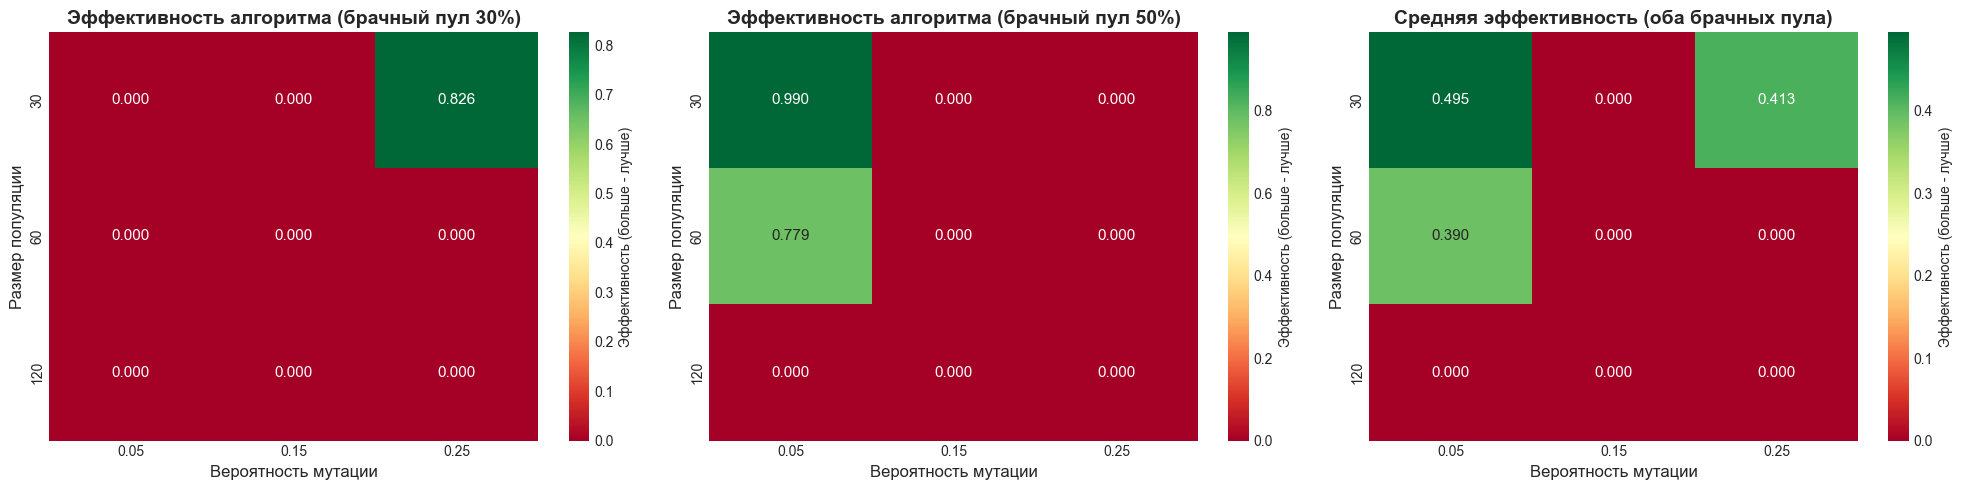

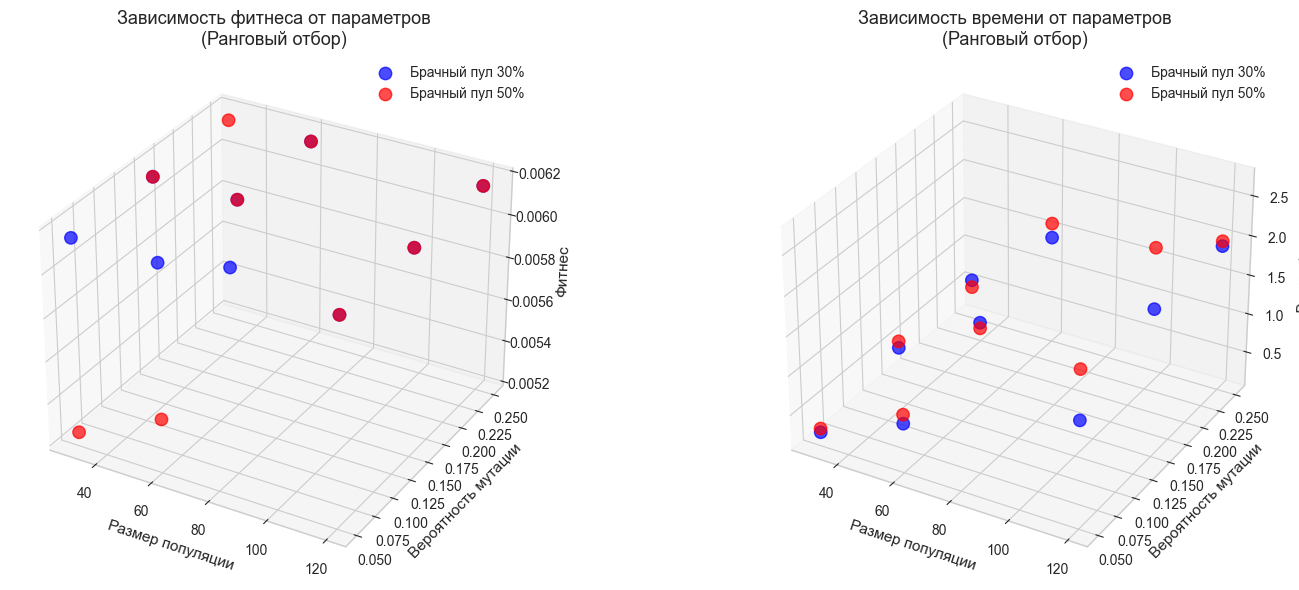

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from mpl_toolkits.mplot3d import Axes3D

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")


fig3 = plt.figure(figsize=(20, 5))

scaler = MinMaxScaler()
results_df['norm_fitness'] = 1 - scaler.fit_transform(results_df[['best_fitness']]).ravel()
results_df['norm_time'] = 1 - scaler.fit_transform(results_df[['execution_time']]).ravel()
results_df['efficiency'] = np.sqrt(results_df['norm_fitness'] * results_df['norm_time'])

ax1 = plt.subplot(1, 3, 1)
pivot_eff_30 = results_df[results_df['mating_pool_ratio'] == 0.3].pivot_table(
    values='efficiency',
    index='population_size',
    columns='mutation_prob',
    aggfunc='mean'
)
sns.heatmap(pivot_eff_30, annot=True, fmt='.3f', cmap='RdYlGn', 
            cbar_kws={'label': 'Эффективность (больше - лучше)'}, ax=ax1,
            annot_kws={'size': 11})
ax1.set_title('Эффективность алгоритма (брачный пул 30%)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Вероятность мутации', fontsize=12)
ax1.set_ylabel('Размер популяции', fontsize=12)

ax2 = plt.subplot(1, 3, 2)
pivot_eff_50 = results_df[results_df['mating_pool_ratio'] == 0.5].pivot_table(
    values='efficiency',
    index='population_size',
    columns='mutation_prob',
    aggfunc='mean'
)
sns.heatmap(pivot_eff_50, annot=True, fmt='.3f', cmap='RdYlGn', 
            cbar_kws={'label': 'Эффективность (больше - лучше)'}, ax=ax2,
            annot_kws={'size': 11})
ax2.set_title('Эффективность алгоритма (брачный пул 50%)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Вероятность мутации', fontsize=12)
ax2.set_ylabel('Размер популяции', fontsize=12)

ax3 = plt.subplot(1, 3, 3)
pivot_eff_combined = results_df.pivot_table(
    values='efficiency',
    index='population_size',
    columns='mutation_prob',
    aggfunc='mean'
)
sns.heatmap(pivot_eff_combined, annot=True, fmt='.3f', cmap='RdYlGn', 
            cbar_kws={'label': 'Эффективность (больше - лучше)'}, ax=ax3,
            annot_kws={'size': 11})
ax3.set_title('Средняя эффективность (оба брачных пула)', fontsize=14, fontweight='bold')
ax3.set_xlabel('Вероятность мутации', fontsize=12)
ax3.set_ylabel('Размер популяции', fontsize=12)

plt.tight_layout()
plt.show()



fig = plt.figure(figsize=(16, 6))

ax1 = fig.add_subplot(121, projection='3d')
for mating_ratio in MATING_POOL_RATIOS:
    subset = results_df[results_df['mating_pool_ratio'] == mating_ratio]
    ax1.scatter(subset['population_size'], subset['mutation_prob'], 
                subset['best_fitness'], 
                label=f'Брачный пул {mating_ratio:.0%}',
                s=80, alpha=0.7, 
                color='red' if mating_ratio == 0.5 else 'blue')
ax1.set_xlabel('Размер популяции', fontsize=11)
ax1.set_ylabel('Вероятность мутации', fontsize=11)
ax1.set_zlabel('Фитнес', fontsize=11)
ax1.set_title('Зависимость фитнеса от параметров\n(Ранговый отбор)', fontsize=13)
ax1.legend()

ax2 = fig.add_subplot(122, projection='3d')
for mating_ratio in MATING_POOL_RATIOS:
    subset = results_df[results_df['mating_pool_ratio'] == mating_ratio]
    ax2.scatter(subset['population_size'], subset['mutation_prob'], 
                subset['execution_time'], 
                label=f'Брачный пул {mating_ratio:.0%}',
                s=80, alpha=0.7,
                color='red' if mating_ratio == 0.5 else 'blue')
ax2.set_xlabel('Размер популяции', fontsize=11)
ax2.set_ylabel('Вероятность мутации', fontsize=11)
ax2.set_zlabel('Время (сек)', fontsize=11)
ax2.set_title('Зависимость времени от параметров\n(Ранговый отбор)', fontsize=13)
ax2.legend()

plt.tight_layout()
plt.show()

Вывод: наиболее качественное решение находится при вероятности мутации 0.25, малого размера популяции и большого брачного пула, потому что высокая мутация позволяет как можно больше охватить пространство поиска, а малая популяция быстрее адаптироваться к изменениям

In [12]:
def population(food: List[int], count: int, size: int) -> List[List[int]]:
    population: List[List[int]] = []
    while len(population) < count:
        element: List[int] = [-1] * size
        to = size
        for position in range(to):
            value = generator.choice(range(len(food)))
            element[position] = food[value]
        population.append(element)
    return population



res = population(list(df.index.values), 10000, 4)
display(len(res))
display(my_print(df, res))


10000

[['банан', 'банан', 'гречка с курицей', 'макароны с фаршем'],
 ['апельсин', 'овсяная каша', 'йогурт', 'банан'],
 ['банан', 'бутерброд с сыром', 'банан', 'апельсин'],
 ['банан', 'овсяная каша', 'каша рисовая на молоке', 'гречка с курицей'],
 ['рыба с рисом', 'рыба с рисом', 'каша рисовая на молоке', 'йогурт'],
 ['овсяная каша', 'банан', 'йогурт', 'груша'],
 ['творог', 'гречка с курицей', 'апельсин', 'суп куриный с лапшой'],
 ['овощной салат', 'творог', 'банан', 'гречка с курицей'],
 ['груша', 'рыба с рисом', 'каша рисовая на молоке', 'бутерброд с сыром'],
 ['суп куриный с лапшой', 'суп куриный с лапшой', 'груша', 'рыба с рисом'],
 ['макароны с фаршем', 'бутерброд с сыром', 'омлет с сыром', 'яблоко'],
 ['каша рисовая на молоке',
  'каша рисовая на молоке',
  'творог',
  'рыба с рисом'],
 ['бутерброд с сыром', 'орехи', 'апельсин', 'банан'],
 ['рыба с рисом',
  'яблоко',
  'каша рисовая на молоке',
  'каша рисовая на молоке'],
 ['рыба с рисом', 'овощной салат', 'каша рисовая на молоке', 'а

In [18]:
fitness_results = []

for chromosome in res:
    fitness_results.append(1 / (my_fitness(chromosome, df) + 0.000001))

In [ ]:
print(f"Максимальный фитнес: {np.max(fitness_results):.5f}")

Максимальный фитнес: 0.00615


In [39]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from typing import List, Tuple

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")


def population(food: List[int], count: int, size: int) -> List[List[int]]:
    population: List[List[int]] = []
    while len(population) < count:
        element: List[int] = [-1] * size
        to = size
        for position in range(to):
            value = generator.choice(range(len(food)))
            element[position] = food[value]
        population.append(element)
    return population

start_time_random = time.time()
random_solutions = population(list(df.index.values), 10000, 4)
end_time_random = time.time()

print(f"Время генерации: {end_time_random - start_time_random:.4f} сек")

print("\nфитнес-функция")

fitness_results = []
fitness_raw = []
execution_times = []

start_time_fitness = time.time()

for i, chromosome in enumerate(random_solutions):
    start_iter = time.time()
    
    raw_fitness = my_fitness(chromosome, df)
    transformed_fitness = 1 / (raw_fitness + 0.000001)
    
    fitness_raw.append(raw_fitness)
    fitness_results.append(transformed_fitness)
    execution_times.append(time.time() - start_iter)
    

end_time_fitness = time.time()

print(f"\nВремя вычисления фитнеса: {end_time_fitness - start_time_fitness:.4f} сек")
print(f"Среднее время на одно решение: {np.mean(execution_times)*1000:.4f} мс")


Время генерации: 0.2816 сек

фитнес-функция

Время вычисления фитнеса: 11.1824 сек
Среднее время на одно решение: 1.1173 мс


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


fitness_results = np.array(fitness_results)
fitness_raw = np.array(fitness_raw)

stats_random = {
    'mean': np.mean(fitness_results),
    'median': np.median(fitness_results),
    'std': np.std(fitness_results),
    'min': np.min(fitness_results),
    'max': np.max(fitness_results),
    'skewness': stats.skew(fitness_results),
    'kurtosis': stats.kurtosis(fitness_results)
}

print("\nСтатистики случайных решений:")
for key, value in stats_random.items():
    print(f"  {key}: {value:.6f}")


ga_best_fitness = 0.00615 
ga_best_fitness_raw = (1 / ga_best_fitness) - 0.000001
ga_time = 0.45
ga_population_size = 30
ga_generations = 12

print("\nСравнение с ГА:")
print(f"ГА:     {ga_best_fitness:.6f}")
print(f"Случайный (max): {stats_random['max']:.6f}")
print(f"Случайный (mean): {stats_random['mean']:.6f}")
print(f"Случайный (median): {stats_random['median']:.6f}")


n_products = len(df)
chromosome_length = 4
search_space_size = n_products ** chromosome_length

avg_time_per_solution = np.mean(execution_times)

exhaustive_time = search_space_size * avg_time_per_solution


print(f"\nВременные оценки:")
print(f"  Среднее время на решение: {avg_time_per_solution*1000:.4f} мс")
print(f"  Время полного перебора: {exhaustive_time:.2f} сек ({exhaustive_time/3600:.2f} часов)")

print(f"\nСравнение времени:")
print(f"  ГА (лучшая конфигурация): {ga_time:.2f} сек")
print(f"  Случайный поиск (10000): {end_time_fitness - start_time_fitness:.2f} сек")
print(f"  Полный перебор (оценка): {exhaustive_time:.2f} сек")

speedup_vs_random = (end_time_fitness - start_time_fitness) / ga_time
speedup_vs_exhaustive = exhaustive_time / ga_time


Статистики случайных решений:
  mean: 0.000894
  median: 0.000801
  std: 0.000486
  min: 0.000024
  max: 0.006150
  skewness: 3.400725
  kurtosis: 23.263068

Сравнение с ГА:
ГА:     0.006150
Случайный (max): 0.006150
Случайный (mean): 0.000894
Случайный (median): 0.000801

Временные оценки:
  Среднее время на решение: 1.1173 мс
  Время полного перебора: 73.22 сек (0.02 часов)

Сравнение времени:
  ГА (лучшая конфигурация): 0.45 сек
  Случайный поиск (10000): 11.18 сек
  Полный перебор (оценка): 73.22 сек


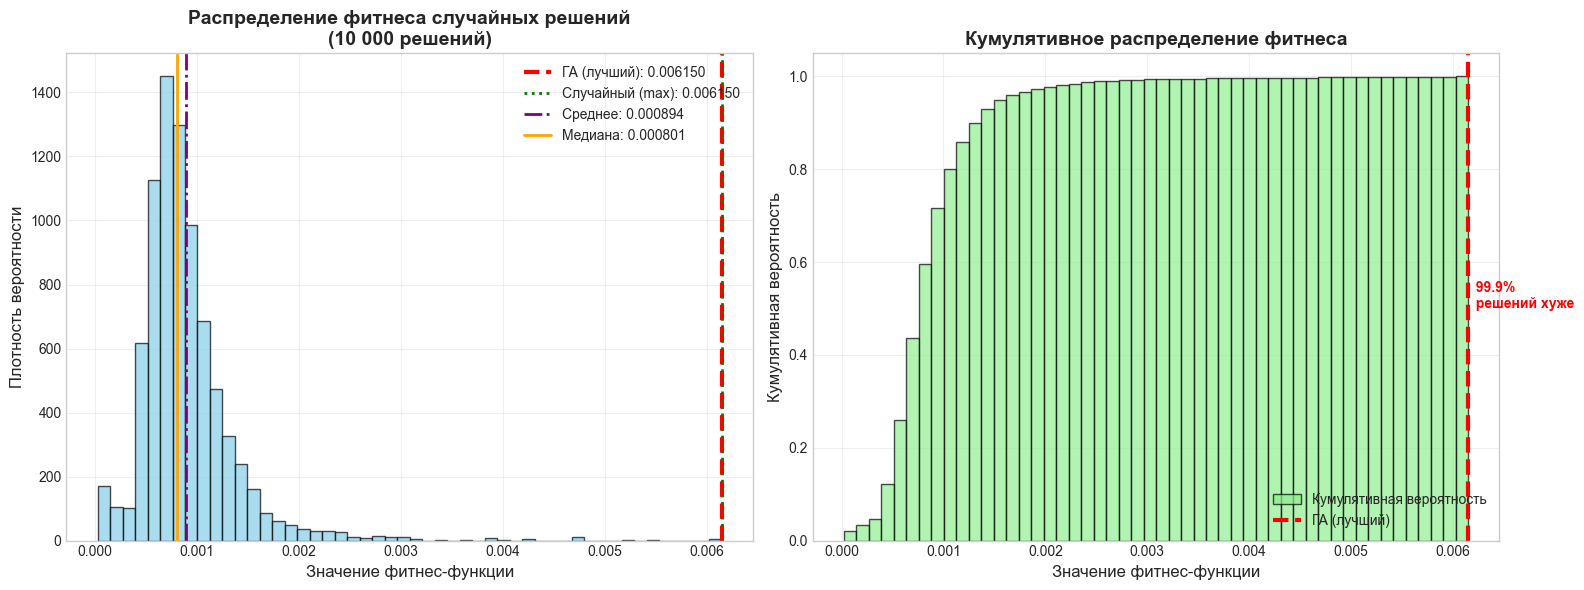

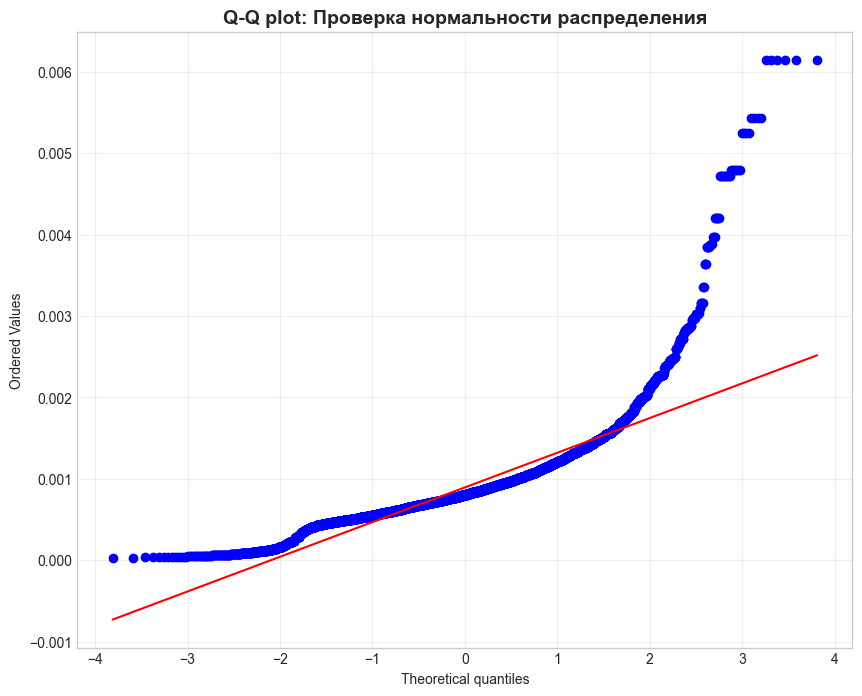

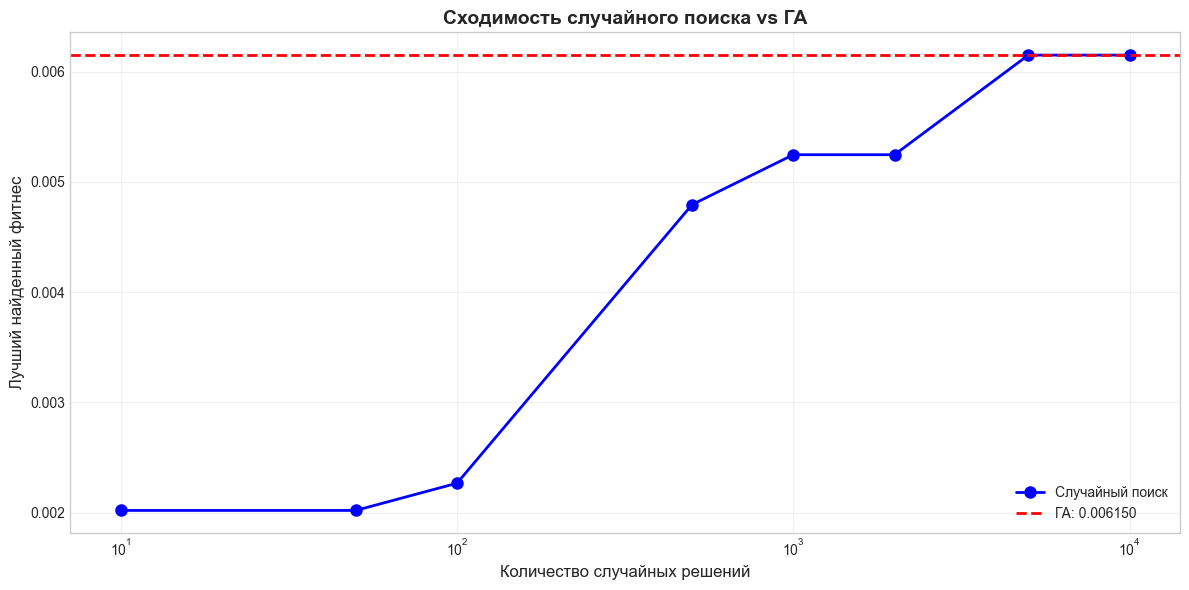

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = axes[0]
n_bins = 50
counts, bins, patches = ax1.hist(fitness_results, bins=n_bins, 
                                  color='skyblue', edgecolor='black', 
                                  alpha=0.7, density=True)

ax1.axvline(x=ga_best_fitness, color='red', linestyle='--', 
            linewidth=3, label=f'ГА (лучший): {ga_best_fitness:.6f}')
ax1.axvline(x=stats_random['max'], color='green', linestyle=':', 
            linewidth=2, label=f'Случайный (max): {stats_random["max"]:.6f}')
ax1.axvline(x=stats_random['mean'], color='purple', linestyle='-.', 
            linewidth=2, label=f'Среднее: {stats_random["mean"]:.6f}')
ax1.axvline(x=stats_random['median'], color='orange', linestyle='-', 
            linewidth=2, label=f'Медиана: {stats_random["median"]:.6f}')

ax1.set_xlabel('Значение фитнес-функции', fontsize=12)
ax1.set_ylabel('Плотность вероятности', fontsize=12)
ax1.set_title('Распределение фитнеса случайных решений\n(10 000 решений)', 
              fontsize=14, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)


ax2 = axes[1]
counts, bins, patches = ax2.hist(fitness_results, bins=n_bins, 
                                  color='lightgreen', edgecolor='black', 
                                  alpha=0.7, cumulative=True, density=True,
                                  label='Кумулятивная вероятность')

ax2.axvline(x=ga_best_fitness, color='red', linestyle='--', 
            linewidth=3, label=f'ГА (лучший)')


ga_percentile = stats.percentileofscore(fitness_results, ga_best_fitness)
ax2.text(ga_best_fitness, 0.5, f'  {ga_percentile:.1f}%\n  решений хуже', 
         fontsize=10, color='red', fontweight='bold')

ax2.set_xlabel('Значение фитнес-функции', fontsize=12)
ax2.set_ylabel('Кумулятивная вероятность', fontsize=12)
ax2.set_title('Кумулятивное распределение фитнеса', fontsize=14, fontweight='bold')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)




plt.tight_layout()
plt.savefig('random_vs_ga_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
stats.probplot(fitness_results, dist="norm", plot=ax)
ax.set_title('Q-Q plot: Проверка нормальности распределения', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.show()

sample_sizes = [10, 50, 100, 500, 1000, 2000, 5000, 10000]
best_so_far_random = []

for n in sample_sizes:
    subset = fitness_results[:n]
    best_so_far_random.append(np.max(subset))



fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(sample_sizes, best_so_far_random, 'b-o', linewidth=2, markersize=8, 
        label='Случайный поиск')
ax.axhline(y=ga_best_fitness, color='red', linestyle='--', linewidth=2, 
           label=f'ГА: {ga_best_fitness:.6f}')

ax.set_xlabel('Количество случайных решений', fontsize=12)
ax.set_ylabel('Лучший найденный фитнес', fontsize=12)
ax.set_title('Сходимость случайного поиска vs ГА', fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('convergence_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
